In [2]:
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from utils.draw_map import draw_map

In [3]:
pkl_path = "data/LSWMD.pkl"
df = pd.read_pickle(pkl_path)
print(f"[WM-811K] Loaded {len(df):,} rows")

[WM-811K] Loaded 811,457 rows


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 811457 entries, 0 to 811456
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   waferMap        811457 non-null  object 
 1   dieSize         811457 non-null  float64
 2   lotName         811457 non-null  object 
 3   waferIndex      811457 non-null  float64
 4   trianTestLabel  811457 non-null  object 
 5   failureType     811457 non-null  object 
dtypes: float64(2), object(4)
memory usage: 37.1+ MB


In [5]:
df['failureType'].explode().value_counts()

failureType
[none]         147431
[Edge-Ring]      9680
[Edge-Loc]       5189
[Center]         4294
[Loc]            3593
[Scratch]        1193
[Random]          866
[Donut]           555
[Near-full]       149
Name: count, dtype: int64

In [6]:
def extract_label(val) -> str:
    """failureType is stored as a nested array like [['Center']] or an empty array."""
    while isinstance(val, (np.ndarray, list)):
        if len(val) == 0:
            return "unlabeled"
        val = val[0]
    return str(val).strip() or "unlabeled"

df["failureType"] = df["failureType"].apply(extract_label)
df['failureType'].value_counts()

failureType
unlabeled    638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

In [7]:
mask = (df["failureType"] == "unlabeled").map({True: "unlabeled", False: "labeled"})
pd.DataFrame({
    "count": mask.value_counts(),
    "percent": mask.value_counts(normalize=True).mul(100).round(2),
})

,count,percent
failureType,,
unlabeled,638507,78.69
labeled,172950,21.31


In [8]:
df_labeled = df[df["failureType"] != "unlabeled"].reset_index(drop=True)
counts = df_labeled["failureType"].value_counts()
pd.DataFrame({
    "count": counts,
    "percent": df_labeled["failureType"].value_counts(normalize=True).mul(100).round(2),
})

,count,percent
failureType,,
none,147431,85.24
Edge-Ring,9680,5.60
Edge-Loc,5189,3.00
Center,4294,2.48
Loc,3593,2.08
Scratch,1193,0.69
Random,866,0.50
Donut,555,0.32
Near-full,149,0.09


In [9]:
df_labeled['dieSize'].describe()

count    172950.000000
mean       1042.232374
std        1032.572449
min           3.000000
25%         533.000000
50%         776.000000
75%        1250.000000
max       22372.000000
Name: dieSize, dtype: float64

In [10]:
df_labeled["map_shape"] = df_labeled["waferMap"].apply(lambda m: m.shape)

print("Distinct shapes:", df_labeled["map_shape"].nunique())
df_labeled["map_shape"].value_counts().head(10)

Distinct shapes: 346


map_shape
(25, 27)    18781
(26, 26)    14366
(30, 34)    12400
(29, 26)    11751
(27, 25)    10682
(39, 37)    10173
(33, 29)     8125
(42, 44)     6724
(44, 41)     6134
(41, 33)     5091
Name: count, dtype: int64

In [11]:
smallest = df_labeled.loc[df_labeled["dieSize"].idxmin(), "map_shape"]
largest  = df_labeled.loc[df_labeled["dieSize"].idxmax(), "map_shape"]

print("Smallest shape:", smallest)
print("Largest shape:", largest)

Smallest shape: (15, 3)
Largest shape: (153, 187)


In [12]:
df_labeled.nsmallest(10, 'dieSize')[['map_shape', 'dieSize']]

,map_shape,dieSize
109448,"(15, 3)",3.0
34396,"(24, 13)",34.0
34826,"(24, 18)",34.0
34839,"(18, 4)",54.0
117873,"(27, 15)",154.0
136868,"(18, 44)",173.0
113489,"(27, 25)",439.0
115486,"(27, 25)",439.0
113727,"(27, 25)",443.0
114418,"(27, 25)",444.0


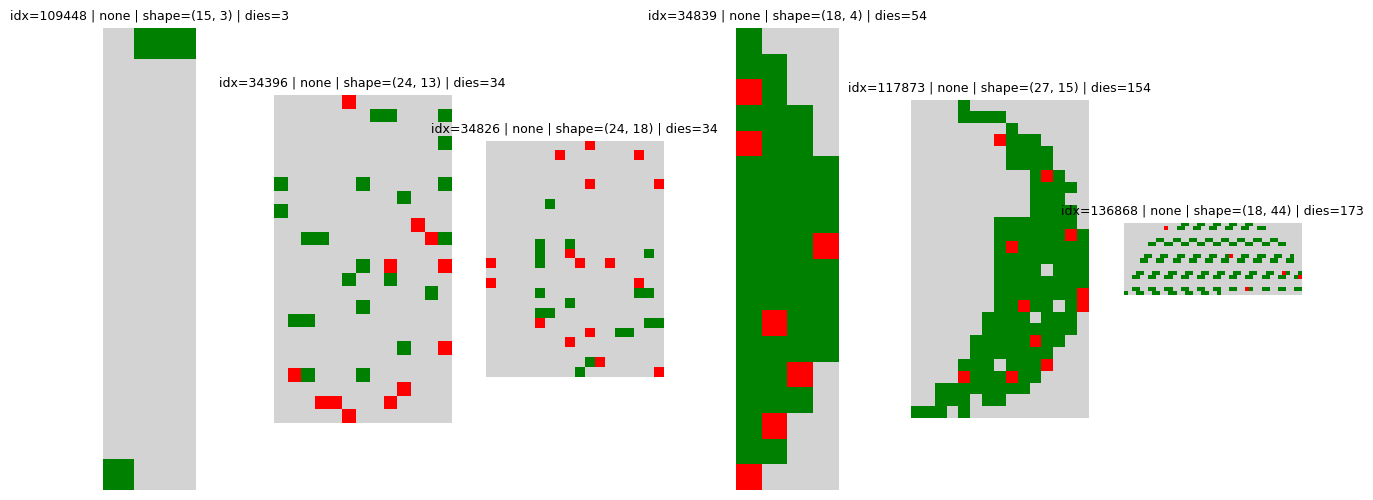

In [13]:
small_maps = df_labeled.nsmallest(10, 'dieSize')
fig, axes = plt.subplots(1, 6, figsize=(16, 6))
for ax, idx in zip(axes, small_maps.index[:6]):
    draw_map(idx, df=df_labeled, ax=ax)
plt.show()

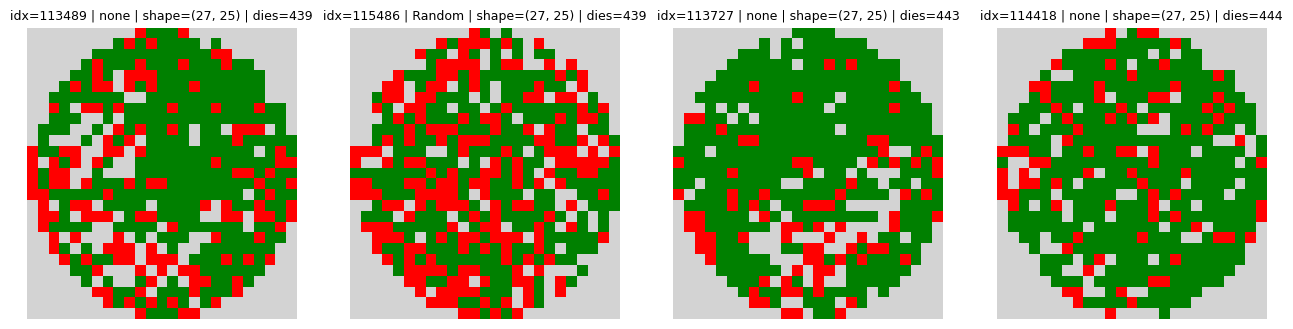

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 6))
for ax, idx in zip(axes, small_maps.index[6:]):
    draw_map(idx, df=df_labeled, ax=ax)
plt.show()

In [15]:
df_clean = df_labeled.drop(df_labeled.nsmallest(6, 'dieSize').index)

In [16]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 172944 entries, 0 to 172949
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   waferMap        172944 non-null  object 
 1   dieSize         172944 non-null  float64
 2   lotName         172944 non-null  object 
 3   waferIndex      172944 non-null  float64
 4   trianTestLabel  172944 non-null  object 
 5   failureType     172944 non-null  object 
 6   map_shape       172944 non-null  object 
dtypes: float64(2), object(5)
memory usage: 10.6+ MB


In [17]:
df_clean['failureType'].value_counts()

failureType
none         147425
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

# Preprocessing

We need to standardise the input (waferMap) for the CNN. Currently, they all have different dimension (`waferMap.shape`)

In [18]:
df_clean['map_shape'].value_counts().head(15)

map_shape
(25, 27)    18781
(26, 26)    14366
(30, 34)    12400
(29, 26)    11751
(27, 25)    10682
(39, 37)    10173
(33, 29)     8125
(42, 44)     6724
(44, 41)     6134
(41, 33)     5091
(35, 31)     4331
(25, 26)     4174
(41, 38)     4152
(33, 37)     3729
(29, 27)     2872
Name: count, dtype: int64

looking at the most common shapes/dimensions, `64x64` would be the most suitable. We will use `cv2` to resize the maps
- first, we pad all the maps to ensure they are a square
- then, we scale them to the given size

In [19]:
IMG_SIZE = 64

def pad_to_square(m):
    m = np.asarray(m, dtype=np.uint8)
    h, w = m.shape
    s = max(h, w)
    top, left = (s - h) // 2, (s - w) // 2
    return np.pad(m, ((top, s - h - top), (left, s - w - left)), constant_values=0)

def preprocess_map(m, size=IMG_SIZE):
    return cv2.resize(pad_to_square(m), (size, size), interpolation=cv2.INTER_NEAREST)

In [20]:
df_clean["waferMap_64"] = df_clean["waferMap"].apply(preprocess_map)


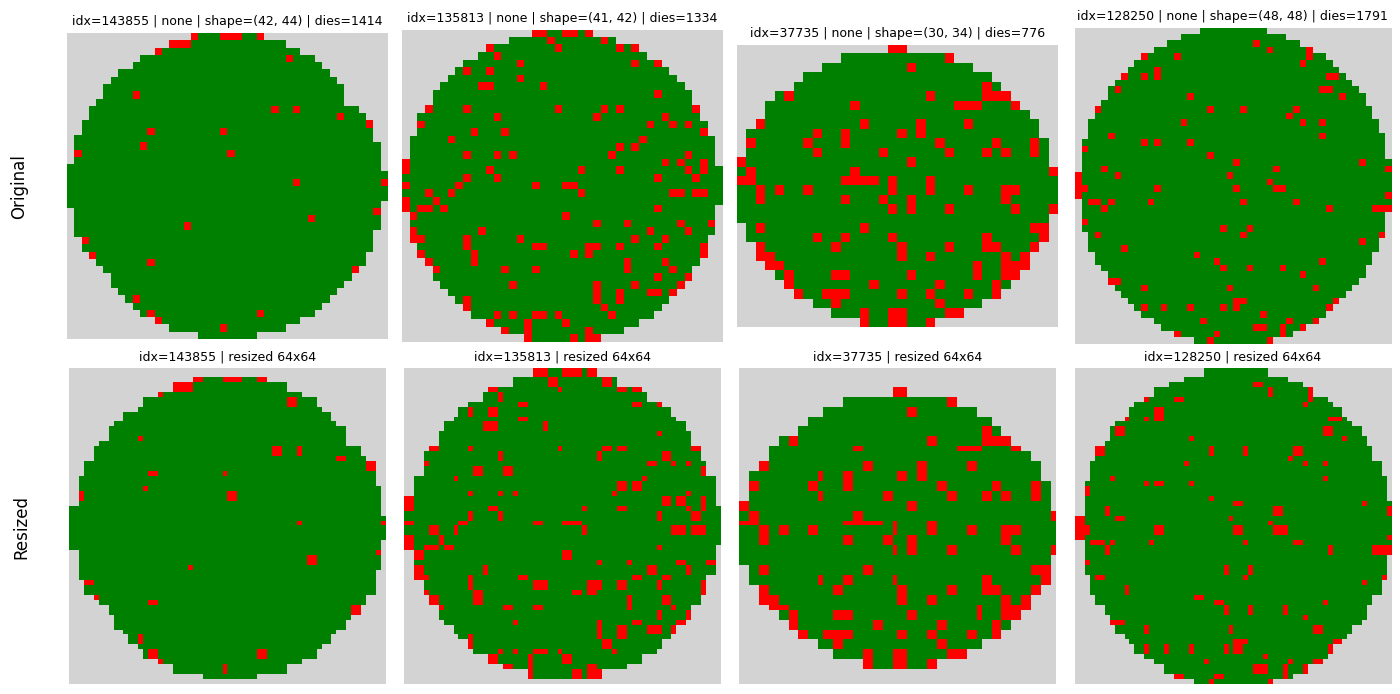

In [21]:
sample_idx = df_clean.sample(4).index   # add random_state=42 for repeatable picks

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for col, idx in enumerate(sample_idx):
    draw_map(idx, df=df_clean, ax=axes[0, col])
    draw_map(df_clean.loc[idx, "waferMap_64"], ax=axes[1, col],
             title=f"idx={idx} | resized {IMG_SIZE}x{IMG_SIZE}")

axes[0, 0].text(-0.15, 0.5, "Original", transform=axes[0, 0].transAxes,
                rotation=90, ha="center", va="center", fontsize=12)
axes[1, 0].text(-0.15, 0.5, "Resized", transform=axes[1, 0].transAxes,
                rotation=90, ha="center", va="center", fontsize=12)

plt.tight_layout()
plt.show()

# Train, Validate & Test

now, we will split into the 3 categories

## 1. Encode labels and stack the maps

In [22]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split

classes = sorted(df_clean["failureType"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

X = np.stack(df_clean["waferMap_64"].values).astype(np.uint8)   # (N, 64, 64)
y = df_clean["failureType"].map(class_to_idx).values

In [23]:
print(classes)
print(class_to_idx)
print(y)

['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-full', 'Random', 'Scratch', 'none']
{'Center': 0, 'Donut': 1, 'Edge-Loc': 2, 'Edge-Ring': 3, 'Loc': 4, 'Near-full': 5, 'Random': 6, 'Scratch': 7, 'none': 8}
[8 8 8 ... 3 2 3]


## 2. Dataset with optional augmentation

The maps are stored as uint8 to save memory. All 170k as float32 would take about 2.8 GB. Each map is converted to float only when it’s loaded. Augmentation applies a random rotation and flip each time a sample is drawn, so the model sees different variants across epochs:

In [24]:
class WaferDataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y).long()
        self.augment = augment

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.X[i].float().unsqueeze(0) / 2.0   # (1, 64, 64), values 0, 0.5, 1
        if self.augment:
            x = torch.rot90(x, torch.randint(4, (1,)).item(), dims=(1, 2))
            if torch.rand(1).item() < 0.5:
                x = torch.flip(x, dims=(2,))
        return x, self.y[i]

## 3. Stratified 70 / 10 / 20 split

In [25]:
idx = np.arange(len(y))
train_idx, test_idx = train_test_split(idx, test_size=0.2, stratify=y, random_state=42)
train_idx, val_idx = train_test_split(train_idx, test_size=0.125, stratify=y[train_idx], random_state=42)
# 0.125 of the remaining 80% = 10% of the total

train_ds = WaferDataset(X[train_idx], y[train_idx], augment=True)
val_ds   = WaferDataset(X[val_idx],   y[val_idx])
test_ds  = WaferDataset(X[test_idx],  y[test_idx])

## 4. DataLoaders with a balanced sampler for training

`WeightedRandomSampler` draws rare classes more often, which takes the place of the manual undersampling and oversampling from earlier. Combined with the on-the-fly augmentation, repeated Near-full maps show up in different orientations.

In [26]:
counts = np.bincount(y[train_idx], minlength=len(classes))
weights = 1.0 / np.sqrt(counts)            # softened; use 1.0 / counts for fully balanced
sample_weights = torch.tensor(weights[y[train_idx]], dtype=torch.double)

sampler = WeightedRandomSampler(sample_weights, num_samples=len(train_idx), replacement=True)

train_loader = DataLoader(train_ds, batch_size=64, sampler=sampler)
val_loader   = DataLoader(val_ds,   batch_size=256, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False)

## 5. Check the result

In [27]:
for name, ids in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    print(name, len(ids), dict(zip(classes, np.bincount(y[ids], minlength=len(classes)))))

xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)                            # torch.Size([64, 1, 64, 64]) torch.Size([64])
print(np.bincount(yb.numpy(), minlength=len(classes)))   # should look much less skewed than the raw data

train 121060 {'Center': np.int64(3006), 'Donut': np.int64(388), 'Edge-Loc': np.int64(3632), 'Edge-Ring': np.int64(6776), 'Loc': np.int64(2515), 'Near-full': np.int64(104), 'Random': np.int64(606), 'Scratch': np.int64(836), 'none': np.int64(103197)}
val 17295 {'Center': np.int64(429), 'Donut': np.int64(56), 'Edge-Loc': np.int64(519), 'Edge-Ring': np.int64(968), 'Loc': np.int64(359), 'Near-full': np.int64(15), 'Random': np.int64(87), 'Scratch': np.int64(119), 'none': np.int64(14743)}
test 34589 {'Center': np.int64(859), 'Donut': np.int64(111), 'Edge-Loc': np.int64(1038), 'Edge-Ring': np.int64(1936), 'Loc': np.int64(719), 'Near-full': np.int64(30), 'Random': np.int64(173), 'Scratch': np.int64(238), 'none': np.int64(29485)}
torch.Size([64, 1, 64, 64]) torch.Size([64])
[ 5  1  3 10  6  1  2  3 33]


save to file

In [ ]:
np.savez_compressed(
    "data/wm811k_clean.npz",
    X=X,                       # (N, 64, 64) uint8
    y=y,                       # (N,) int labels
    classes=np.array(classes),
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
)